# Slide-seqV2 → Celldega preprocessing

This notebook is tailored to the public Slide-seqV2 data format used in the Stickels et al. analysis notebooks.

It follows the same computational model used in both:

- `SlideseqV2_HDST_comparison_submission.ipynb`
- `SlideseqV2_visium_comparison_submission.ipynb`

The important Slide-seqV2 structure is:

```text
digital_expression.txt.gz
    genes × bead barcodes
            ↓ transpose
    beads × genes

bead_locations.csv
    barcode → x, y
```

The DGE and coordinates are joined by **barcode**.

Because Slide-seq does not provide exact molecule locations, Celldega pseudo-transcripts are generated by jittering the bead-level counts around each bead coordinate.

This notebook also:

- estimates bead spacing from the data
- chooses jitter relative to bead spacing
- shifts coordinates to a positive local canvas
- optionally makes a transparent dummy image and Celldega image pyramid
- optionally creates circular **bead footprints** as a boundary layer
- writes Celldega gene metadata and bead-by-gene parquets
- writes jittered transcript tiles using absolute tile indices

> The generated transcript coordinates are visualization surrogates, not measured molecular coordinates.


In [1]:
import pyvips
print(pyvips.__version__)
print(pyvips.Image)

3.2.0
<class 'pyvips.vimage.Image'>


In [2]:
from pathlib import Path
import json
import re

import celldega as dega
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from matplotlib.colors import to_hex
from PIL import Image
from scipy import sparse
from scipy.spatial import cKDTree
from shapely.geometry import Point

print("Celldega version:", dega.__version__)


Celldega version: 0.25.0a2


## 1. Configuration

For your downloaded SCP815 example, the two required files are:

```text
Puck_190921_19.digital_expression.txt.gz
Puck_190921_19_bead_locations.csv
```

Change only these paths initially.


In [3]:
sample = "Puck_190921_19"

data_dir = Path("SCP815/other")
dge_path = data_dir / f"{sample}.digital_expression.txt.gz"
coords_path = data_dir / f"{sample}_bead_locations.csv"

output_root = Path("DegaFiles")
path_landscape_files = output_root / sample
path_landscape_files.mkdir(parents=True, exist_ok=True)

# Celldega tile size in the FINAL coordinate system.
tile_size = 500

# Shift the puck into a positive local canvas.
# This is useful because the public bead coordinates do not need to share
# an origin with an external tissue image.
normalize_origin = True
canvas_margin = 100

# Jitter pseudo-transcripts relative to estimated bead-to-bead spacing.
# Example: 0.35 means jitter scale ~= 35% of the median nearest-neighbor spacing.
jitter_fraction_of_spacing = 0.35
random_seed = 0

# Optional background image.
make_dummy_image = True
dummy_image_layer = "background"

# Optional: visualize each bead as a circular boundary.
# These are bead footprints, NOT segmented cells.
write_bead_boundaries = True
bead_radius_fraction_of_spacing = 0.45

print("DGE:", dge_path)
print("Coordinates:", coords_path)
print("Output:", path_landscape_files)


DGE: SCP815/other/Puck_190921_19.digital_expression.txt.gz
Coordinates: SCP815/other/Puck_190921_19_bead_locations.csv
Output: DegaFiles/Puck_190921_19


## 2. Helpers


In [4]:
def make_unique(names):
    seen = {}
    out = []
    for x in map(str, names):
        n = seen.get(x, 0)
        out.append(x if n == 0 else f"{x}_{n}")
        seen[x] = n + 1
    return out


def to_absolute_tile_bounds(min_val, max_val, tile_size):
    abs_min = int(np.floor(min_val / tile_size) * tile_size)
    abs_max = int(np.floor(max_val / tile_size) * tile_size + tile_size)
    return abs_min, abs_max


def rename_local_tiles_to_absolute(tile_dir, prefix, offset_i, offset_j):
    if offset_i == 0 and offset_j == 0:
        return 0

    tile_dir = Path(tile_dir)
    pattern = re.compile(
        rf"^{re.escape(prefix)}_tile_(-?\d+)_(-?\d+)\.parquet$"
    )

    files = [f for f in tile_dir.iterdir() if pattern.match(f.name)]
    temp = []

    for f in files:
        m = pattern.match(f.name)
        i, j = int(m.group(1)), int(m.group(2))
        tmp = f.with_name(f.name + ".tmpmove")
        f.rename(tmp)
        temp.append((tmp, i, j))

    for tmp, i, j in temp:
        final = tmp.with_name(
            f"{prefix}_tile_{i + offset_i}_{j + offset_j}.parquet"
        )
        tmp.rename(final)

    return len(temp)


def count_rows_in_tiles(tile_dir, prefix):
    tile_dir = Path(tile_dir)
    pattern = re.compile(
        rf"^{re.escape(prefix)}_tile_(-?\d+)_(-?\d+)\.parquet$"
    )
    total = 0
    for f in tile_dir.iterdir():
        if pattern.match(f.name):
            total += pq.ParquetFile(f).metadata.num_rows
    return total


def load_public_slideseq_dge(path):
    """
    Load the public Slide-seqV2 digital_expression.txt.gz format.

    The reference notebooks show two closely related pandas-loading variants:
      1. read with index_col=0, then transpose
      2. read normally, transpose, promote the first row to columns, drop it

    This function handles both layouts and returns beads x genes.
    """

    raw = pd.read_csv(
        path,
        sep="\t",
        header=0,
        compression="infer",
        low_memory=False,
    )

    print("Raw DGE shape:", raw.shape)
    print("First raw columns:", raw.columns[:5].tolist())

    # Most public DGE files have the first column as the gene name column.
    first_col = raw.columns[0]

    # If the first column is clearly nonnumeric, treat it as gene names.
    if (
        raw[first_col].dtype == object
        or str(first_col).lower() in {"gene", "genes", "gene_name", "gene_names"}
    ):
        genes = raw[first_col].astype(str).tolist()
        counts = raw.drop(columns=[first_col])

        counts.index = make_unique(genes)
        dge = counts.T
    else:
        # Fallback matching the Visium-comparison notebook:
        # transpose, promote first row to gene names, then drop it.
        tmp = raw.T
        tmp.columns = make_unique(tmp.iloc[0].astype(str))
        dge = tmp.iloc[1:].copy()

    dge.index = dge.index.astype(str)
    dge.index.name = "barcode"
    dge.columns = make_unique(dge.columns.astype(str))

    # Ensure numeric counts.
    dge = dge.apply(pd.to_numeric, errors="raise")

    return dge


def load_public_bead_locations(path):
    """
    Robustly load the public *_bead_locations.csv file.

    Expected logical fields:
        barcode, x, y

    The exact public column names can vary, so this inspects the table and
    falls back to sensible positional interpretation.
    """

    coords = pd.read_csv(path)
    print("Coordinate file columns:", coords.columns.tolist())
    print("Coordinate file shape:", coords.shape)

    lower = {str(c).lower(): c for c in coords.columns}

    barcode_candidates = [
        "barcode", "barcodes", "bead_barcode", "beadbarcode"
    ]
    x_candidates = [
        "x", "xcoord", "x_coord", "x_coordinate", "xpos", "x_pos"
    ]
    y_candidates = [
        "y", "ycoord", "y_coord", "y_coordinate", "ypos", "y_pos"
    ]

    barcode_col = next((lower[x] for x in barcode_candidates if x in lower), None)
    x_col = next((lower[x] for x in x_candidates if x in lower), None)
    y_col = next((lower[x] for x in y_candidates if x in lower), None)

    if barcode_col is None or x_col is None or y_col is None:
        # Public Slide-seq coordinate files are often simple 3-column tables.
        if coords.shape[1] >= 3:
            print(
                "Could not identify all coordinate columns by name; "
                "falling back to a 3-column format."
            )

            # Find the barcode-like string column.
            string_cols = [
                c for c in coords.columns
                if coords[c].dtype == object
            ]

            if len(string_cols) == 1:
                barcode_col = string_cols[0]
                numeric_cols = [c for c in coords.columns if c != barcode_col]
                x_col, y_col = numeric_cols[:2]
            else:
                # Common exported layout: x, y, barcode OR barcode, x, y.
                # Inspect the first few values for DNA-like barcode strings.
                def barcode_score(series):
                    vals = series.dropna().astype(str).head(100)
                    if len(vals) == 0:
                        return 0
                    return np.mean(
                        vals.str.fullmatch(r"[ACGTN]+", case=False).fillna(False)
                    )

                scores = {c: barcode_score(coords[c]) for c in coords.columns}
                barcode_col = max(scores, key=scores.get)
                remaining = [c for c in coords.columns if c != barcode_col]
                x_col, y_col = remaining[:2]
        else:
            raise ValueError(
                "Could not identify barcode/x/y columns in bead_locations.csv."
            )

    out = coords[[barcode_col, x_col, y_col]].copy()
    out.columns = ["barcode", "x", "y"]

    out["barcode"] = out["barcode"].astype(str)
    out["x"] = pd.to_numeric(out["x"], errors="raise")
    out["y"] = pd.to_numeric(out["y"], errors="raise")

    out = out.drop_duplicates("barcode").set_index("barcode")

    print(
        f"Using columns: barcode={barcode_col!r}, "
        f"x={x_col!r}, y={y_col!r}"
    )

    return out


def estimate_bead_spacing(spots, max_points=50000):
    xy = spots[["x", "y"]].to_numpy(float)

    if len(xy) > max_points:
        rng = np.random.default_rng(0)
        xy = xy[rng.choice(len(xy), max_points, replace=False)]

    tree = cKDTree(xy)
    distances, _ = tree.query(xy, k=2)

    # nearest neighbor excluding self
    nn = distances[:, 1]
    nn = nn[np.isfinite(nn) & (nn > 0)]

    return float(np.median(nn))


## 3. Load the Slide-seqV2 DGE

The Stickels comparison notebooks transpose the digital-expression matrix so that the observations become bead barcodes.


In [22]:
dge = load_public_slideseq_dge(dge_path)

print("Bead × gene DGE:", dge.shape)
display(dge.iloc[:5, :5])

print("\nFirst bead barcodes:")
print(dge.index[:5].tolist())

print("\nFirst genes:")
print(dge.columns[:10].tolist())


Raw DGE shape: (22683, 33612)
First raw columns: ['Row', 'ACGATCCAAAAACN', 'CGGTCCTACCCCCT', 'ACCTTAGACCCCAA', 'TCCTCCACTTTTTT']
Bead × gene DGE: (33611, 22683)


,0610005C13Rik,0610007P14Rik,0610009B22Rik,0610009E02Rik,0610009L18Rik
barcode,,,,,
ACGATCCAAAAACN,0,0,0,0,0
CGGTCCTACCCCCT,0,0,0,0,0
ACCTTAGACCCCAA,0,0,0,0,0
TCCTCCACTTTTTT,0,0,0,0,0
ACCCGCTACCCCCT,0,0,0,0,0



First bead barcodes:
['ACGATCCAAAAACN', 'CGGTCCTACCCCCT', 'ACCTTAGACCCCAA', 'TCCTCCACTTTTTT', 'ACCCGCTACCCCCT']

First genes:
['0610005C13Rik', '0610007P14Rik', '0610009B22Rik', '0610009E02Rik', '0610009L18Rik', '0610009O20Rik', '0610010F05Rik', '0610010K14Rik', '0610011F06Rik', '0610025J13Rik']


## 4. Load bead positions and join by barcode

This is the key operation used in the published comparison notebooks as well: coordinates and expression are aligned by the bead barcode, not by row position.


In [23]:
coords = load_public_bead_locations(coords_path)

print("\nCoordinates:")
display(coords.head())

common = dge.index.intersection(coords.index)

print(f"DGE beads:        {len(dge):,}")
print(f"Coordinate beads: {len(coords):,}")
print(f"Matched beads:    {len(common):,}")

if len(common) == 0:
    raise ValueError(
        "No bead barcodes match between the DGE and coordinate file."
    )

match_fraction = len(common) / len(dge)
print(f"Fraction of DGE beads with coordinates: {match_fraction:.2%}")

# Keep only spatially placeable beads and force identical ordering.
dge = dge.loc[common].copy()
spots_original = coords.loc[common, ["x", "y"]].copy()

assert dge.index.equals(spots_original.index)


Coordinate file columns: ['barcodes', 'xcoord', 'ycoord']
Coordinate file shape: (33611, 3)
Using columns: barcode='barcodes', x='xcoord', y='ycoord'

Coordinates:


,x,y
barcode,,
ACGATCCAAAAACN,4384.141026,2775.358974
CGGTCCTACCCCCT,3940.031646,5275.734177
ACCTTAGACCCCAA,3186.365079,774.920635
TCCTCCACTTTTTT,2043.488889,4715.733333
ACCCGCTACCCCCT,3187.634615,770.711538


DGE beads:        33,611
Coordinate beads: 33,611
Matched beads:    33,611
Fraction of DGE beads with coordinates: 100.00%


## 5. Count QC

Use raw integer UMI counts here — not normalized or log-transformed values.


,x,y,total_counts,n_genes
count,33611.000000,33611.000000,33611.000000,33611.000000
mean,3382.357486,3326.565965,413.598435,329.134063
std,1200.592635,1184.776375,418.417220,299.665785
min,12.413793,69.802469,20.000000,3.000000
25%,2440.004349,2430.166379,109.000000,100.000000
50%,3415.732283,3375.698925,288.000000,247.000000
75%,4344.337871,4267.848476,577.000000,468.000000
max,6027.589041,6027.637931,4564.000000,2634.000000


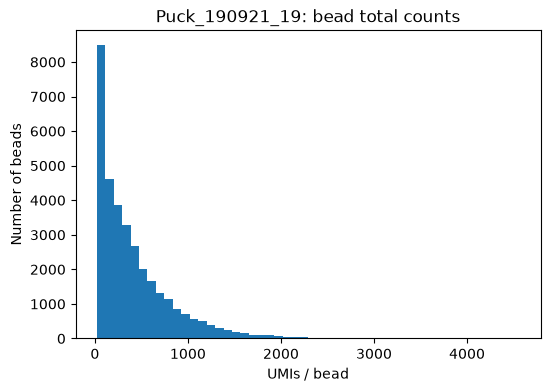

In [24]:
# Check integer-like and nonnegative.
arr = dge.to_numpy()

if np.nanmin(arr) < 0:
    raise ValueError("Negative expression values detected.")

if not np.allclose(arr, np.round(arr)):
    raise ValueError(
        "The DGE contains non-integer values. "
        "Use the raw digital-expression count matrix."
    )

total_counts = dge.sum(axis=1)
n_genes = (dge > 0).sum(axis=1)

qc = spots_original.copy()
qc["total_counts"] = total_counts
qc["n_genes"] = n_genes

display(qc.describe())

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(qc["total_counts"], bins=50)
ax.set_xlabel("UMIs / bead")
ax.set_ylabel("Number of beads")
ax.set_title(f"{sample}: bead total counts")
plt.show()


## 6. Prepare coordinates for Celldega

The published notebooks use the bead coordinates directly for spatial plots.

For Celldega we optionally translate the puck into a positive local canvas. This changes only the origin, not the geometry or relative distances.


In [25]:
spots = spots_original.copy()

if normalize_origin:
    spots["x"] = spots["x"] - spots["x"].min() + canvas_margin
    spots["y"] = spots["y"] - spots["y"].min() + canvas_margin

print("Original coordinate range:")
print(
    f"x = {spots_original['x'].min():.3f} .. {spots_original['x'].max():.3f}"
)
print(
    f"y = {spots_original['y'].min():.3f} .. {spots_original['y'].max():.3f}"
)

print("\nCelldega coordinate range:")
print(f"x = {spots['x'].min():.3f} .. {spots['x'].max():.3f}")
print(f"y = {spots['y'].min():.3f} .. {spots['y'].max():.3f}")

bead_spacing = estimate_bead_spacing(spots)
jitter = bead_spacing * jitter_fraction_of_spacing
bead_radius = bead_spacing * bead_radius_fraction_of_spacing

print(f"Estimated median nearest-neighbor bead spacing: {bead_spacing:.3f}")
print(f"Pseudo-transcript jitter: {jitter:.3f}")
print(f"Bead footprint radius: {bead_radius:.3f}")


Original coordinate range:
x = 12.414 .. 6027.589
y = 69.802 .. 6027.638

Celldega coordinate range:
x = 100.000 .. 6115.175
y = 100.000 .. 6057.835
Estimated median nearest-neighbor bead spacing: 15.247
Pseudo-transcript jitter: 5.336
Bead footprint radius: 6.861


## 7. Spatial sanity check


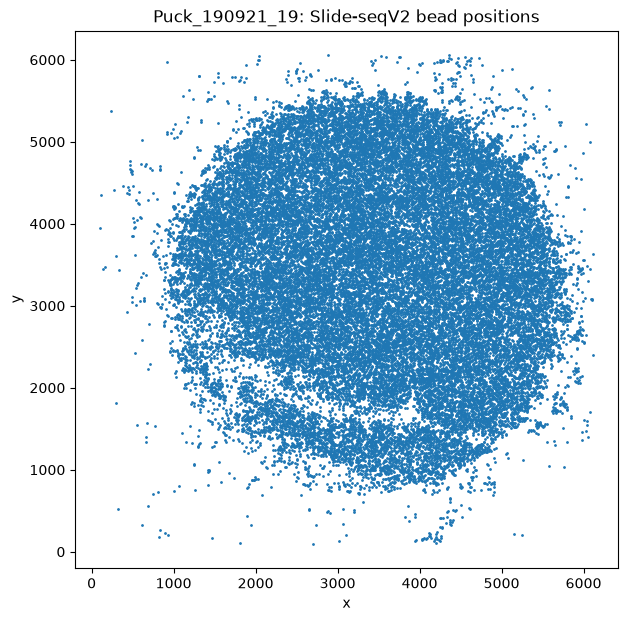

In [26]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(
    spots["x"],
    spots["y"],
    s=1,
)
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"{sample}: Slide-seqV2 bead positions")

# Many image-derived coordinate systems have y increasing downward.
# If the puck looks vertically flipped relative to a future image,
# uncomment this:
# ax.invert_yaxis()

plt.show()


## 8. Convert the DGE to a pandas sparse DataFrame

The public DGE is easy to inspect as a dense DataFrame, but Celldega pseudo-transcript generation is much more memory-efficient with sparse storage.


In [27]:
X = sparse.csr_matrix(dge.to_numpy(dtype=np.int32))

sbg = pd.DataFrame.sparse.from_spmatrix(
    X,
    index=dge.index.astype(str),
    columns=dge.columns.astype(str),
)

spots = spots.loc[sbg.index].copy()

print("Sparse bead × gene matrix:", sbg.shape)
print("Nonzero bead-gene entries:", sbg.sparse.to_coo().nnz)
print("Total counts:", int(sbg.sparse.to_coo().sum()))


Sparse bead × gene matrix: (33611, 22683)
Nonzero bead-gene entries: 11062525
Total counts: 13901457


## 9. Create a transparent dummy image and Celldega image pyramid

Slide-seq does not require a tissue image. If Celldega expects an image layer, this creates a transparent canvas that covers the puck coordinate extent.

The canvas dimensions are inferred from the bead coordinates.


In [12]:
image_info = []
max_pyramid_zoom = None

if make_dummy_image:
    width = int(np.ceil(spots["x"].max() + canvas_margin))
    height = int(np.ceil(spots["y"].max() + canvas_margin))

    print(f"Dummy canvas: {width} × {height}")

    dummy_png = path_landscape_files / "transparent_dummy.png"

    # RGBA with alpha = 0.
    img = Image.new("RGBA", (width, height), (255, 255, 255, 0))
    img.save(dummy_png)

    pyramid_dir = path_landscape_files / "pyramid_images"

    dega.pre.make_deepzoom_pyramid(
        str(dummy_png),
        str(pyramid_dir),
        dummy_image_layer,
        suffix=".webp[Q=100]",
    )

    max_pyramid_zoom = dega.pre.get_max_zoom_level(
        str(pyramid_dir / f"{dummy_image_layer}_files")
    )

    image_info = [
        {
            "name": dummy_image_layer,
            "button_name": dummy_image_layer.upper(),
            "color": [255, 255, 255],
        }
    ]

    print("max_pyramid_zoom:", max_pyramid_zoom)
else:
    print("Skipping dummy image.")


Dummy canvas: 6216 × 6158
max_pyramid_zoom: 13


## 10. Create gene metadata


In [13]:
genes = sbg.columns.astype(str).tolist()

palettes = [
    plt.get_cmap(name).colors
    for name in plt.colormaps()
    if "tab" in name and hasattr(plt.get_cmap(name), "colors")
]
flat_colors = [c for palette in palettes for c in palette]
flat_hex = [to_hex(c) for c in flat_colors]

meta_gene = pd.DataFrame(index=genes)
meta_gene["mean"] = 100.0
meta_gene["std"] = 10.0
meta_gene["max"] = 100.0
meta_gene["non-zero"] = 0.5
meta_gene["color"] = [
    flat_hex[i % len(flat_hex)]
    for i in range(len(genes))
]

meta_gene_path = path_landscape_files / "meta_gene.parquet"
meta_gene.to_parquet(meta_gene_path)

# Replace placeholder statistics with actual matrix-derived values.
dega.pre.make_meta_gene(
    sbg,
    str(meta_gene_path),
)

display(pd.read_parquet(meta_gene_path).head())



========Write meta gene files========
cbg is a dense DataFrame. Proceeding with dense operations.
Calculating mean expression
Calculating variance
All meta gene files are succesfully saved.


,mean,std,max,non-zero,color
0610005C13Rik,0.0,0.006640,1.0,0.00003,#e55050
0610007P14Rik,0.0,0.143024,3.0,0.00003,#e55050
0610009B22Rik,0.0,0.158243,3.0,0.00003,#e55050
0610009E02Rik,0.0,0.076573,3.0,0.00003,#e55050
0610009L18Rik,0.0,0.080502,2.0,0.00003,#e55050


## 12. Optional bead-footprint boundary layer

Slide-seq does not have segmented cells. If enabled, this section creates one circular polygon per bead, with radius based on the median nearest-neighbor spacing.

These polygons should be interpreted as **capture-bead footprints**, not biological cell boundaries.


In [32]:
if write_bead_boundaries:
    cell_segmentation_dir = path_landscape_files / "cell_segmentation"
    cell_clusters_dir = path_landscape_files / "cell_clusters"

    cell_segmentation_dir.mkdir(parents=True, exist_ok=True)
    cell_clusters_dir.mkdir(parents=True, exist_ok=True)

    # bead_ids = pd.Index([f"bead_{x}" for x in spots.index.astype(str)])
    bead_ids = pd.Index(
            spots.index.astype(str)
        )

    # Celldega metadata.
    bead_meta = pd.DataFrame({
        "name": bead_ids,
        "geometry": [
            [float(x), float(y)]
            for x, y in spots[["x", "y"]].to_numpy()
        ],
    })
    bead_meta.to_parquet(
        path_landscape_files / "cell_metadata.parquet",
        index=False,
    )

    clusters = pd.DataFrame(
        {"cluster": pd.Series("0", index=bead_ids, dtype="string")}
    )
    clusters.to_parquet(cell_clusters_dir / "cluster.parquet")

    meta_cluster = pd.DataFrame(
        {"color": ["#ff7f0e"], "count": [len(bead_ids)]},
        index=["0"],
    )
    meta_cluster.to_parquet(cell_clusters_dir / "meta_cluster.parquet")

    # Trigger Celldega's integer-name mapping.
    name_mapping = dega.pre.boundary_tile._get_name_mapping(
        str(path_landscape_files),
        layer="boundary",
        segmentation="default",
    )

    # Make approximate circular bead footprints.
    polygons = [
        Point(float(x), float(y)).buffer(bead_radius, resolution=8)
        for x, y in spots[["x", "y"]].to_numpy()
    ]

    bead_gdf = gpd.GeoDataFrame(
        {
            "string_name": bead_ids.astype(str),
            "center_x": spots["x"].to_numpy(float),
            "center_y": spots["y"].to_numpy(float),
            "geometry": polygons,
        },
        geometry="geometry",
    )

    bead_gdf["name"] = bead_gdf["string_name"].map(name_mapping)

    if bead_gdf["name"].isna().any():
        raise ValueError("Some bead IDs could not be mapped to integer names.")

    bead_gdf["tile_i"] = np.floor(
        bead_gdf["center_x"] / tile_size
    ).astype(int)
    bead_gdf["tile_j"] = np.floor(
        bead_gdf["center_y"] / tile_size
    ).astype(int)

    for (tile_i, tile_j), group in bead_gdf.groupby(["tile_i", "tile_j"]):
        out = pd.DataFrame({
            "GEOMETRY": [
                dega.pre._round_nested_coord_list([
                    [
                        [float(x), float(y)]
                        for x, y in poly.exterior.coords
                    ]
                ])
                for poly in group.geometry
            ],
            "name": group["name"].astype(int).tolist(),
        })

        out.to_parquet(
            cell_segmentation_dir
            / f"cell_tile_{tile_i}_{tile_j}.parquet",
            index=False,
        )

    print(f"Wrote {len(bead_gdf):,} approximate bead boundaries.")
else:
    print("Skipping bead boundary layer.")


Wrote 33,611 approximate bead boundaries.


## 11. Save bead-by-gene parquets

Celldega calls this a CBG-style layer. Here the observations are **beads rather than cells**.


In [33]:
dega.pre.save_cbg_gene_parquets(
    "IST",
    str(path_landscape_files),
    sbg,
    verbose=True,
)


Processing gene 0: 0610005C13Rik
Processing gene 1000: 4933424M12Rik
Processing gene 2000: Akr1c13
Processing gene 3000: Bccip
Processing gene 4000: Cdx4
Processing gene 5000: Cyp4f17
Processing gene 6000: Elof1
Processing gene 7000: Fyn
Processing gene 8000: Gm14005
Processing gene 9000: Gm24519
Processing gene 10000: Gm37409
Processing gene 11000: Grpel2
Processing gene 12000: Itgam
Processing gene 13000: Mael
Processing gene 14000: Myom1
Processing gene 15000: Pappa
Processing gene 16000: Pptc7
Processing gene 17000: RP24-103L16.5
Processing gene 18000: Rpp21
Processing gene 19000: Slc3a2
Processing gene 20000: Taf6
Processing gene 21000: Trim80
Processing gene 22000: Yaf2
All gene-specific parquet files are successfully saved.


## 13. Write jittered pseudo-transcripts

For a bead with count `N` for a gene, this writes `N` pseudo-transcripts around that bead's `(x, y)` coordinate.

The jitter scale is derived from observed nearest-neighbor bead spacing rather than assuming a particular coordinate unit.


In [28]:
dge_path = "SCP815/other/Puck_190921_19.digital_expression.txt.gz"

dge = pd.read_csv(
    dge_path,
    sep="\t",
    compression="gzip",
    index_col=0,
)

print(dge.shape)
print(dge.index[:5])
print(dge.columns[:5])

(22683, 33611)
Index(['0610005C13Rik', '0610007P14Rik', '0610009B22Rik', '0610009E02Rik',
       '0610009L18Rik'],
      dtype='object', name='Row')
Index(['ACGATCCAAAAACN', 'CGGTCCTACCCCCT', 'ACCTTAGACCCCAA', 'TCCTCCACTTTTTT',
       'ACCCGCTACCCCCT'],
      dtype='object')


In [29]:
# genes x beads  ->  beads x genes
sbg = dge.T

sbg.index.name = "barcode"

In [30]:
print(sbg.shape)
print(sbg.index[:5])
print(spots.index[:5])

(33611, 22683)
Index(['ACGATCCAAAAACN', 'CGGTCCTACCCCCT', 'ACCTTAGACCCCAA', 'TCCTCCACTTTTTT',
       'ACCCGCTACCCCCT'],
      dtype='object', name='barcode')
Index(['ACGATCCAAAAACN', 'CGGTCCTACCCCCT', 'ACCTTAGACCCCAA', 'TCCTCCACTTTTTT',
       'ACCCGCTACCCCCT'],
      dtype='object', name='barcode')


In [31]:
common_beads = sbg.index.intersection(spots.index)

print("Common beads:", len(common_beads))
print("DGE beads:", len(sbg))
print("Coordinate beads:", len(spots))

sbg = sbg.loc[common_beads]
spots = spots.loc[common_beads]

assert sbg.index.equals(spots.index)

Common beads: 33611
DGE beads: 33611
Coordinate beads: 33611


In [32]:
from scipy import sparse

sbg_sparse = sparse.csr_matrix(sbg.values)

sbg = pd.DataFrame.sparse.from_spmatrix(
    sbg_sparse,
    index=sbg.index,
    columns=sbg.columns,
)

In [33]:
print(sbg.shape)
print(sbg.index.equals(spots.index))
print(int(sbg.sparse.to_coo().sum()))

(33611, 22683)
True
13901457


In [40]:
gene_str_to_int = dega.pre.boundary_tile._get_name_mapping(
    str(path_landscape_files),
    layer="transcript",
)

x_min_abs, x_max_abs = to_absolute_tile_bounds(
    spots["x"].min(),
    spots["x"].max(),
    tile_size,
)
y_min_abs, y_max_abs = to_absolute_tile_bounds(
    spots["y"].min(),
    spots["y"].max(),
    tile_size,
)

tile_bounds = {
    "x_min": x_min_abs,
    "x_max": x_max_abs,
    "y_min": y_min_abs,
    "y_max": y_max_abs,
}

print("Transcript tile bounds:", tile_bounds)

trx_dir = path_landscape_files / "transcript_tiles"
trx_dir.mkdir(parents=True, exist_ok=True)

total_input_transcripts = int(sbg.sparse.to_coo().sum())

dega.pre.write_pseudotranscripts_from_sbg(
    spots=spots,
    sbg=sbg,
    gene_str_to_int=gene_str_to_int,
    tile_bounds=tile_bounds,
    tile_size=tile_size,
    path_output=str(trx_dir),
    jitter=jitter,
    coarse_tile_factor=10,
    rng=np.random.default_rng(random_seed),
)

# Current helper writes local tile indices; correct to viewer absolute grid.
offset_i = tile_bounds["x_min"] // tile_size
offset_j = tile_bounds["y_min"] // tile_size

n_renamed = rename_local_tiles_to_absolute(
    trx_dir,
    "transcripts",
    offset_i,
    offset_j,
)

print(f"Renamed {n_renamed:,} transcript tile files.")

n_on_disk = count_rows_in_tiles(trx_dir, "transcripts")

print(f"Input counts:              {total_input_transcripts:,}")
print(f"Pseudo-transcripts saved: {n_on_disk:,}")

if n_on_disk != total_input_transcripts:
    raise ValueError(
        f"Transcript row-count mismatch: "
        f"{total_input_transcripts:,} expected, {n_on_disk:,} written."
    )


Transcript tile bounds: {'x_min': 0, 'x_max': 6500, 'y_min': 0, 'y_max': 6500}
coarse row 0
Renamed 0 transcript tile files.
Input counts:              13,901,457
Pseudo-transcripts saved: 13,901,457


## 14. Save Celldega Landscape parameters


In [41]:
segmentation_approach = ["default"] if write_bead_boundaries else []

landscape_parameters = {
    "technology": "Xenium",
    "segmentation_approach": segmentation_approach,
    "max_pyramid_zoom": max_pyramid_zoom,
    "tile_size": tile_size,
    "image_info": image_info,
    "image_format": ".webp",
    "use_int_index": True,
    "use_row_groups": False,
}

with open(
    path_landscape_files / "landscape_parameters.json",
    "w",
) as f:
    json.dump(landscape_parameters, f, indent=2)

print(json.dumps(landscape_parameters, indent=2))


{
  "technology": "Xenium",
  "segmentation_approach": [
    "default"
  ],
  "max_pyramid_zoom": 13,
  "tile_size": 500,
  "image_info": [
    {
      "name": "background",
      "button_name": "BACKGROUND",
      "color": [
        255,
        255,
        255
      ]
    }
  ],
  "image_format": ".webp",
  "use_int_index": true,
  "use_row_groups": false
}


## 15. Final checks


In [42]:
print("Output:", path_landscape_files)
print()

for p in sorted(path_landscape_files.iterdir()):
    if p.is_dir():
        n = sum(1 for _ in p.iterdir())
        print(f"{p.name}/ ({n} immediate files)")
    else:
        print(p.name)

print("\nDone.")


Output: DegaFiles/Puck_190921_19

.ipynb_checkpoints/ (1 immediate files)
cbg/ (21624 immediate files)
cell_clusters/ (2 immediate files)
cell_metadata.parquet
cell_segmentation/ (149 immediate files)
landscape_parameters.json
meta_gene.parquet
pyramid_images/ (2 immediate files)
transcript_tiles/ (149 immediate files)
transparent_dummy.png

Done.


## Notes

### Why the loader differs from the first notebook

The original generic notebook assumed either `.h5ad` or Matrix Market input. The actual Slide-seqV2 reference notebooks instead work directly with `digital_expression.txt.gz`, transpose the DGE, and align expression to coordinates by bead barcode. This notebook now follows that convention.

### Coordinates

The Stickels example notebooks use the Slide-seq bead coordinates directly for plotting. This notebook therefore does **not** invent a microns-to-pixels conversion.

Instead, it:

1. preserves all relative distances,
2. optionally shifts the coordinate origin,
3. estimates median bead spacing from the actual puck,
4. defines jitter and bead radius relative to that spacing.

If you later obtain a real registered histology image, replace the dummy image and apply the appropriate image-registration transform to the bead coordinates.

### Biological interpretation

- `sbg` / CBG rows = beads, not cells
- boundary circles = bead footprints, not cell segmentations
- pseudo-transcripts = visualization surrogates, not molecule localizations


In [8]:
import anndata as ad
import scanpy as sc
import numpy as np
import pandas as pd
from scipy import sparse

In [51]:
# IMPORTANT: do NOT use sbg.values here.
# That would create a huge dense matrix.

X = sbg.sparse.to_coo().tocsr()

adata = ad.AnnData(
    X=X,
    obs=pd.DataFrame(index=sbg.index.copy()),
    var=pd.DataFrame(index=sbg.columns.copy()),
)

adata.obs_names = sbg.index.astype(str)
adata.var_names = sbg.columns.astype(str)

# Preserve the actual Slide-seq bead coordinates
adata.obsm["spatial"] = spots.loc[
    adata.obs_names, ["x", "y"]
].to_numpy()

adata

AnnData object with n_obs × n_vars = 33611 × 22683
    obsm: 'spatial'

In [53]:
# adata.write("SCP815/other/Puck_190921_19_adata_raw.h5ad")

In [35]:
sc.pp.calculate_qc_metrics(
    adata,
    percent_top=None,
    log1p=False,
    inplace=True,
)

adata.obs[
    ["total_counts", "n_genes_by_counts"]
].describe()

,total_counts,n_genes_by_counts
count,33611.000000,33611.000000
mean,413.598435,329.134063
std,418.417220,299.665785
min,20.000000,3.000000
25%,109.000000,100.000000
50%,288.000000,247.000000
75%,577.000000,468.000000
max,4564.000000,2634.000000


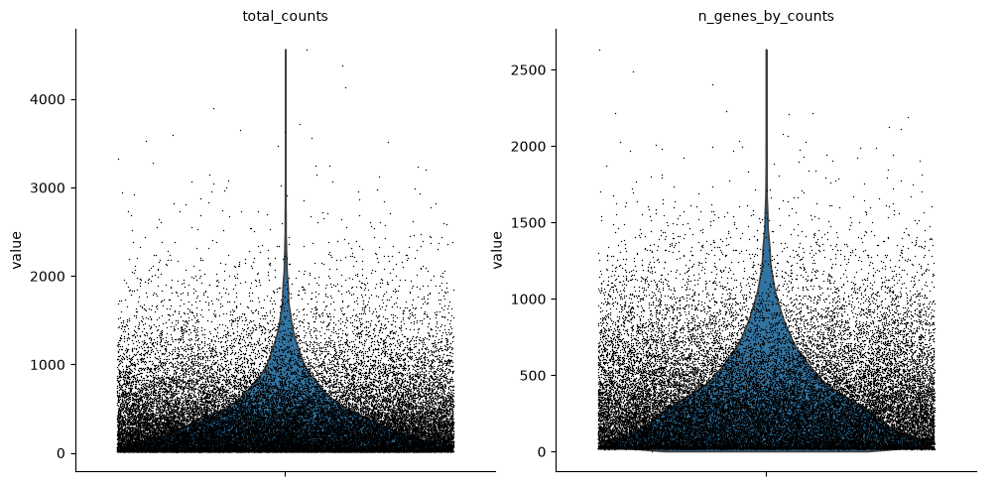

In [36]:
sc.pl.violin(
    adata,
    ["total_counts", "n_genes_by_counts"],
    jitter=0.4,
    multi_panel=True,
)

In [37]:
sc.pp.filter_cells(adata, min_counts=50)
sc.pp.filter_genes(adata, min_cells=10)

adata

AnnData object with n_obs × n_vars = 29007 × 15287
    obs: 'n_genes_by_counts', 'total_counts', 'n_counts'
    var: 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    obsm: 'spatial'

In [38]:
sc.pp.normalize_total(
    adata,
    target_sum=1e4,
)

sc.pp.log1p(adata)

In [39]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=5000,
    flavor="seurat",
)

adata.var["highly_variable"].sum()

np.int64(5000)

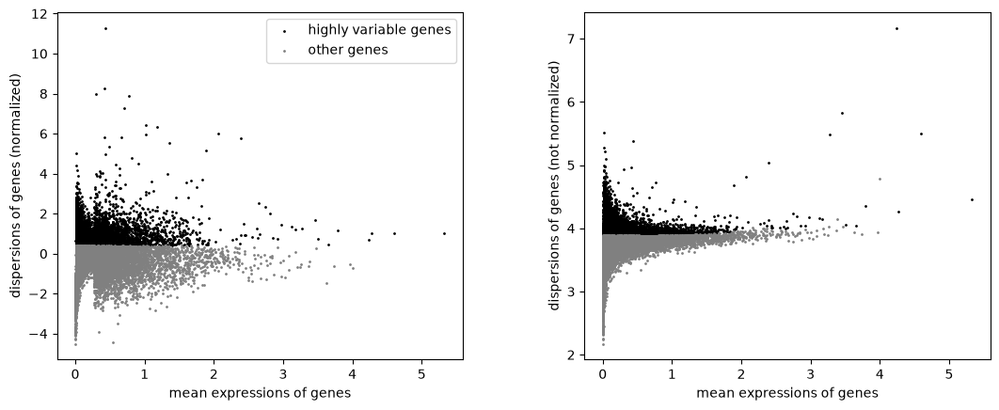

In [40]:
sc.pl.highly_variable_genes(adata)

In [41]:
adata.write("SCP815/other/Puck_190921_19_adata.h5ad")

In [54]:
adata_hvg = adata[:, adata.var["highly_variable"]].copy()

adata_hvg

AnnData object with n_obs × n_vars = 29007 × 5000
    obs: 'n_genes_by_counts', 'total_counts', 'n_counts'
    var: 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'
    obsm: 'spatial'

In [55]:
sc.tl.pca(
    adata_hvg,
    n_comps=50,
    zero_center=False,
    svd_solver="arpack",
)

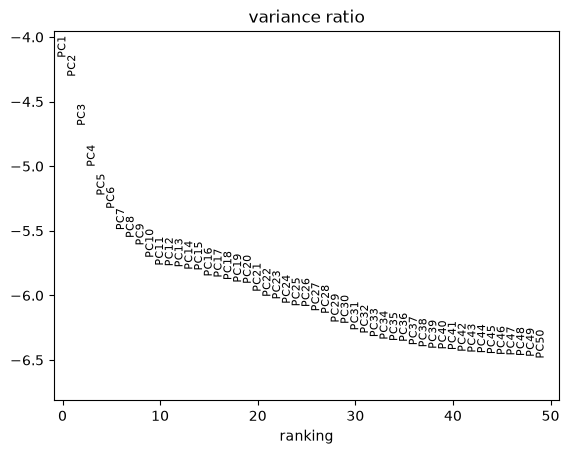

In [56]:
sc.pl.pca_variance_ratio(
    adata_hvg,
    n_pcs=50,
    log=True,
)

In [57]:
sc.pp.neighbors(
    adata_hvg,
    n_neighbors=15,
    n_pcs=30,
)

In [58]:
sc.tl.leiden(
    adata_hvg,
    resolution=1.0,
    key_added="leiden",
)

In [59]:
adata_hvg.obs["leiden"].value_counts().sort_index()

leiden
0     4459
1     3827
2     3381
3     3094
4     2689
5     2613
6     2607
7     2482
8     1446
9      955
10     922
11     532
Name: count, dtype: int64

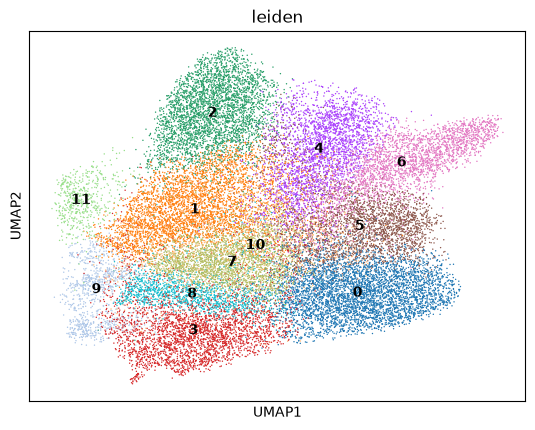

In [60]:
sc.tl.umap(adata_hvg)

sc.pl.umap(
    adata_hvg,
    color="leiden",
    legend_loc="on data",
)

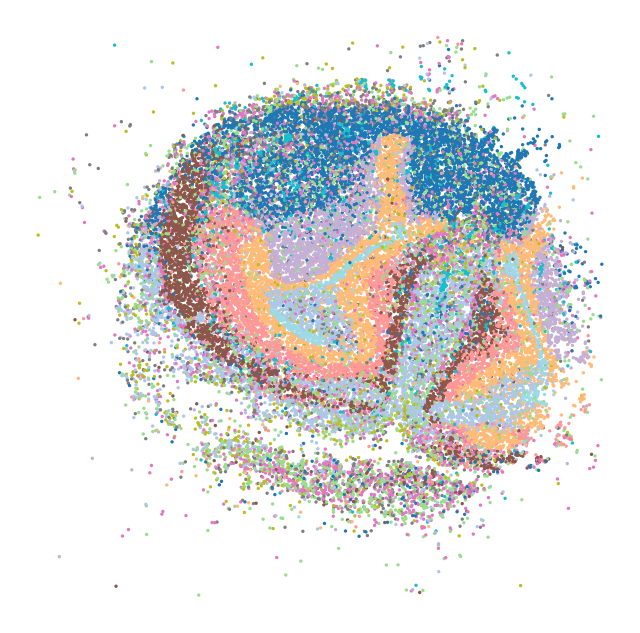

In [61]:
import matplotlib.pyplot as plt

xy = adata_hvg.obsm["spatial"]

clusters = adata_hvg.obs["leiden"].astype("category")
codes = clusters.cat.codes

plt.figure(figsize=(8, 8))

plt.scatter(
    xy[:, 0],
    xy[:, 1],
    c=codes,
    s=2,
    cmap="tab20",
)

plt.gca().set_aspect("equal")
plt.axis("off")
plt.show()

In [9]:
# adata_hvg.write("SCP815/other/Puck_190921_19_adata_HVGs.h5ad")

In [7]:
import numpy as np
import pandas as pd

import scanpy as sc
# ============================================================
# Build adata_full:
#   - all beads
#   - all genes
#   - original spatial coordinates / metadata
#   - clustering results transferred from adata_hvg
# ============================================================

adata_hvg = sc.read_h5ad("SCP815/other/Puck_190921_19_adata_HVGs.h5ad")

# Start from the original AnnData

adata = sc.read_h5ad("SCP815/other/Puck_190921_19_adata_raw.h5ad")

adata_full = adata.copy()

# ------------------------------------------------------------
# 1. Find beads present in both objects
# ------------------------------------------------------------

clustered_beads = adata_full.obs_names.intersection(
    adata_hvg.obs_names
)

print(f"All beads:       {adata_full.n_obs:,}")
print(f"Clustered beads: {len(clustered_beads):,}")
print(
    f"Unclustered:     "
    f"{adata_full.n_obs - len(clustered_beads):,}"
)

# ------------------------------------------------------------
# 2. Transfer obs metadata from clustered AnnData
# ------------------------------------------------------------

for col in adata_hvg.obs.columns:

    # Create column in adata_full if it doesn't already exist
    if col not in adata_full.obs.columns:

        # Use object dtype initially so categories / strings don't cause issues
        adata_full.obs[col] = pd.Series(
            index=adata_full.obs_names,
            dtype="object",
        )

    adata_full.obs.loc[clustered_beads, col] = (
        adata_hvg.obs.loc[clustered_beads, col]
    )

# ------------------------------------------------------------
# 3. Mark beads excluded from clustering as "unclustered"
# ------------------------------------------------------------

if "leiden" in adata_full.obs.columns:

    adata_full.obs["leiden"] = (
        adata_full.obs["leiden"]
        .astype("string")
        .fillna("unclustered")
        .astype("category")
    )

else:
    raise KeyError(
        "'leiden' was not found in adata_hvg.obs. "
        "Make sure clustering was run before creating adata_full."
    )

# ------------------------------------------------------------
# 4. Transfer embeddings from adata_hvg
#
# Clustered beads receive their embedding values.
# Beads excluded from clustering receive NaN.
# ------------------------------------------------------------

for key in ["X_pca", "X_umap"]:

    if key not in adata_hvg.obsm:
        print(f"{key} not found in adata_hvg.obsm — skipping.")
        continue

    source = np.asarray(adata_hvg.obsm[key])

    full_embedding = np.full(
        (adata_full.n_obs, source.shape[1]),
        np.nan,
        dtype=float,
    )

    # positions of common beads in each object
    full_idx = adata_full.obs_names.get_indexer(
        clustered_beads
    )

    hvg_idx = adata_hvg.obs_names.get_indexer(
        clustered_beads
    )

    full_embedding[full_idx] = source[hvg_idx]

    adata_full.obsm[key] = full_embedding

# ------------------------------------------------------------
# 5. Spatial coordinates
#
# These should already exist because adata_full = adata.copy().
# Verify rather than replacing them.
# ------------------------------------------------------------

if "spatial" not in adata_full.obsm:
    raise KeyError(
        "'spatial' is missing from adata_full.obsm."
    )

# ------------------------------------------------------------
# 6. Sanity checks
# ------------------------------------------------------------

print("\nFinal adata_full:")
print(adata_full)

print("\nChecks:")
print(
    "Same number of beads as original:",
    adata_full.n_obs == adata.n_obs,
)

print(
    "Same number of genes as original:",
    adata_full.n_vars == adata.n_vars,
)

print(
    "Spatial shape:",
    adata_full.obsm["spatial"].shape,
)

print("\nLeiden cluster counts:")
print(
    adata_full.obs["leiden"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 7. Optional: verify clustered beads retained their labels
# ------------------------------------------------------------

assert (
    adata_full.obs.loc[clustered_beads, "leiden"]
    .astype(str)
    .values
    ==
    adata_hvg.obs.loc[clustered_beads, "leiden"]
    .astype(str)
    .values
).all()

print("\nCluster labels transferred successfully.")

All beads:       33,611
Clustered beads: 29,007
Unclustered:     4,604

Final adata_full:
AnnData object with n_obs × n_vars = 33611 × 22683
    obs: 'n_genes_by_counts', 'total_counts', 'n_counts', 'leiden'
    obsm: 'spatial', 'X_pca', 'X_umap'

Checks:
Same number of beads as original: True
Same number of genes as original: True
Spatial shape: (33611, 2)

Leiden cluster counts:
leiden
0              4459
1              3827
10              922
11              532
2              3381
3              3094
4              2689
5              2613
6              2607
7              2482
8              1446
9               955
unclustered    4604
Name: count, dtype: int64

Cluster labels transferred successfully.


In [8]:
adata_full.obs.index.name="cell_id"

adata_full.obs['cell_id'] = adata_full.obs.index

cols_to_fill = [
    "n_genes_by_counts",
    "total_counts",
    "n_counts",
]

adata_full.obs[cols_to_fill] = (
    adata_full.obs[cols_to_fill]
    .fillna(0)
)

adata_full.obs[cols_to_fill] = (
    adata_full.obs[cols_to_fill]
    .fillna(0)
    .astype(int)
)

In [9]:
import numpy as np

mat = dega.clust.Matrix(
    adata_full,
    row_attr=["n_cells"],
    col_attr=["cell_area"],
)

mat.downsample_to(category="leiden")

mat.norm(axis="row", by="zscore")

# Remove rows that cannot be used with cosine distance
values = mat.data.to_numpy()

finite_rows = np.isfinite(values).all(axis=1)
nonzero_rows = np.linalg.norm(values, axis=1) > 0

keep = finite_rows & nonzero_rows

print("Rows before:", mat.data.shape[0])
print("Non-finite rows:", (~finite_rows).sum())
print("Zero-vector rows:", (~nonzero_rows).sum())

mat.data = mat.data.loc[keep].copy()
mat.meta_row = mat.meta_row.loc[mat.data.index].copy()

print("Rows after:", mat.data.shape[0])

# Confirm
values = mat.data.to_numpy()

print("All finite:", np.isfinite(values).all())
print("Zero vectors:", (np.linalg.norm(values, axis=1) == 0).sum())

mat.clust()

cgm = dega.viz.Clustergram(
    matrix=mat,
    width=500,
    height=500,
)

cgm

/Users/jishar/Documents/celldega/dega/lib/python3.12/site-packages/celldega/clust/matrix.py:450: UserWarning: Large matrix (33611 x 22683). Consider filtering.
  self.load_adata(data, col_attr=col_attr, row_attr=row_attr)
/Users/jishar/Documents/celldega/dega/lib/python3.12/site-packages/celldega/clust/matrix.py:741: UserWarning: Found 1058 constant features. Replacing zero std with small value to avoid inf/NaN.
  zscore_normalize_inplace(data_values, axis=0)


Rows before: 22683
Non-finite rows: 0
Zero-vector rows: 1058
Rows after: 21625
All finite: True
Zero vectors: 0


In [10]:
# cluster = pd.read_parquet("DegaFiles/Puck_190921_19/cell_clusters/cluster.parquet")
# cluster
# cluster.index.name = ""
# cluster.to_parquet("DegaFiles/Puck_190921_19/cell_clusters/cluster.parquet")

In [11]:
landscape = dega.viz.Landscape(
    technology='Xenium',
    adata=adata_full,
    base_url = f"http://localhost:{dega.viz.get_local_server()}/{path_landscape_files}",
)

/var/folders/_6/bhs42vt57t1dkb59k4sy0p440000gp/T/ipykernel_60111/372773377.py:1: UserWarning: Transformation matrix not found at http://localhost:53990/DegaFiles/Puck_190921_19/micron_to_image_transform.csv. Using identity.
  landscape = dega.viz.Landscape(


In [12]:
dega.viz.landscape_clustergram(
    landscape,
    cgm,
)

In [ ]:
# no background for techs like slide-seq, chromium